> **Versão pública (2026).** Notebook original, executado em 2021 no Windows (Python 3.7, Anaconda), com as bibliotecas na mesma pasta. As saídas são as originais. Para rodar de novo, veja o [README desta pasta](README.md).

In [1]:
import pandas as pd
import numpy as np
import time

from sklearn.model_selection import StratifiedShuffleSplit, ShuffleSplit
from sklearn.model_selection import StratifiedKFold, KFold

######################

import AleTransforms as trf
import AleDatasetAnalysis as dsa

import AleLearners as lrn
import AleMLAnalysis as aml

import AleExplainers as exp

In [2]:
import importlib

importlib.reload(trf)
importlib.reload(dsa)

importlib.reload(lrn)
importlib.reload(aml)

importlib.reload(exp)

<module 'AleExplainers' from '<PASTA_DAS_BIBLIOTECAS>\\AleExplainers.py'>

In [3]:
df = pd.read_csv('datasets/train_titanic.csv')

In [4]:
df = df.drop(['Name', 'Ticket', 'Cabin'], axis = 1)
df.loc[:, df.dtypes == 'int64'] = df.loc[:, df.dtypes == 'int64'].astype(float)

In [5]:
df_nulls = pd.DataFrame(df.isnull().sum(), columns = ['QTD'])
df_nulls = df_nulls[df_nulls['QTD'] > 0]
df_nulls = df_nulls.sort_values('QTD', ascending = True)
display(df_nulls)

,QTD
Embarked,2
Age,177


In [6]:
list(df.columns)

['PassengerId',
 'Survived',
 'Pclass',
 'Sex',
 'Age',
 'SibSp',
 'Parch',
 'Fare',
 'Embarked']

# Análise Exploratória

In [7]:
analise_exp = dsa.DistribuicoesDataset(df, num_div = 10, num_cat = 3)

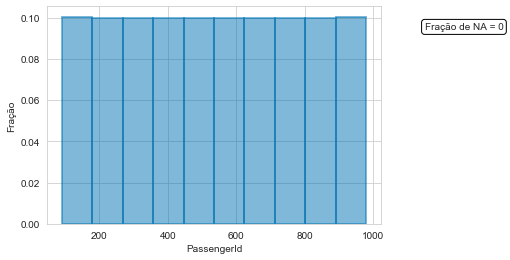

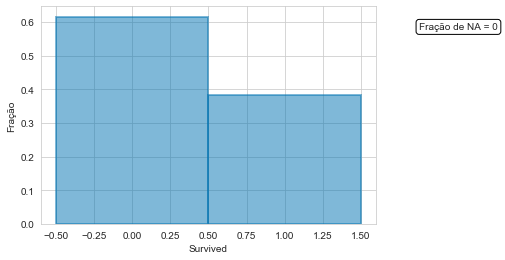

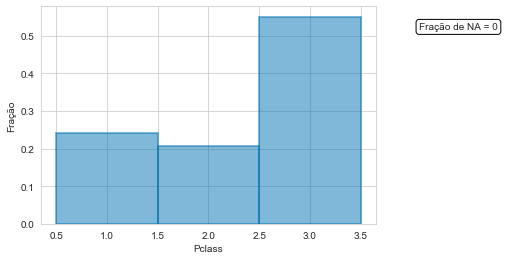

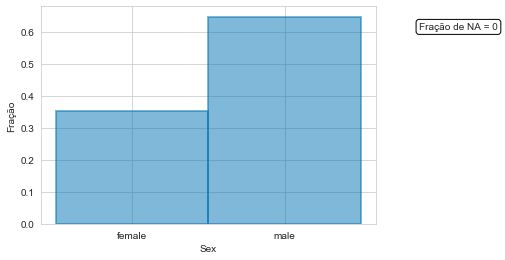

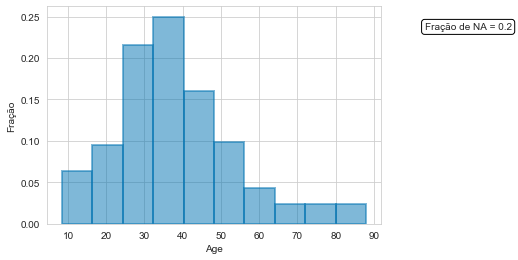

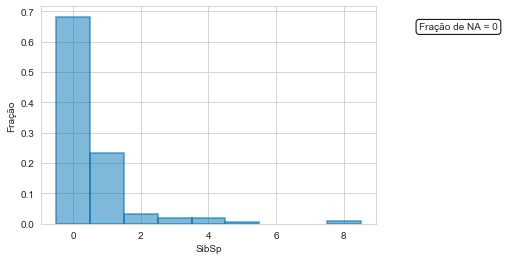

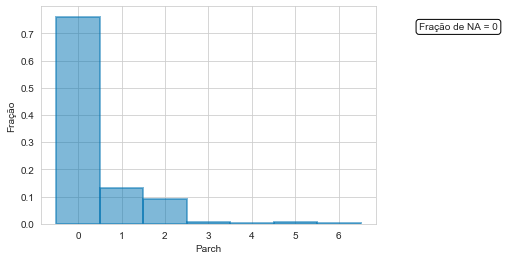

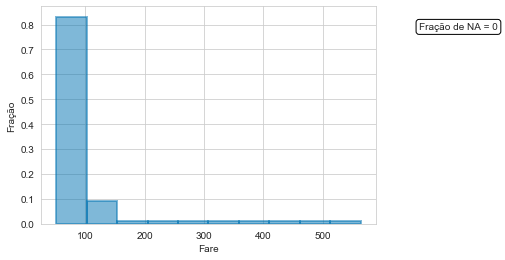

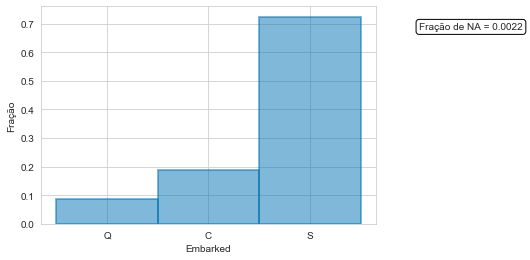

In [8]:
analise_exp.grafico_distribuicao()

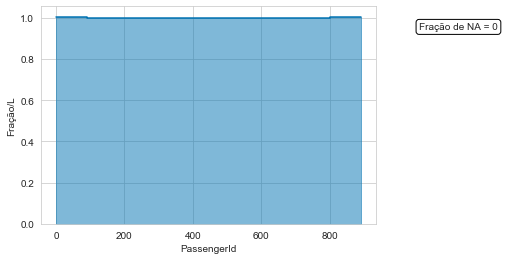

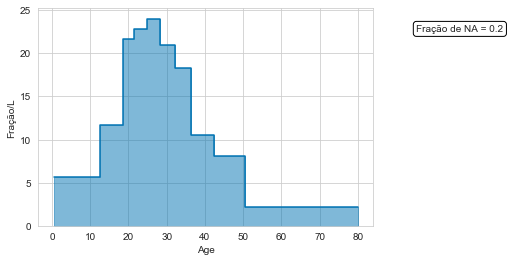

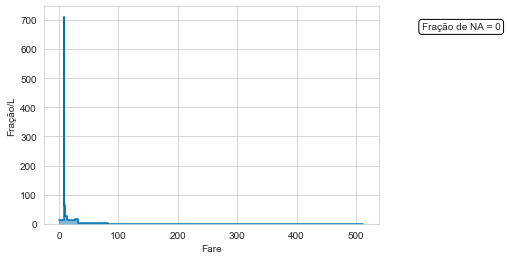

In [9]:
analise_exp.grafico_densidade()

In [10]:
colunas_id = ['PassengerId']
nome_alvo = 'Survived'

In [11]:
dict_dfs = {'Não Sobreviventes': df[df[nome_alvo] == 0],
           'Sobreviventes': df[df[nome_alvo] == 1]}

In [12]:
analise_exp2 = dsa.AvaliaDatasetsDistribuicoes(dict_dfs, num_div = 10, num_cat = 3)

In [13]:
analise_exp2.trata_coluna(dict_dfs, 'Age')

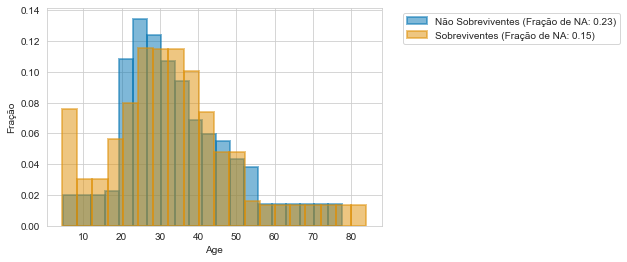

In [14]:
analise_exp2.grafico_distribuicao('Age', bins = 20)

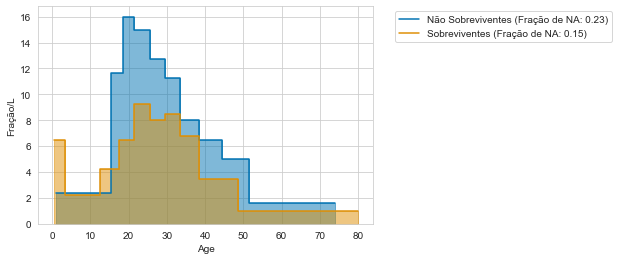

In [15]:
analise_exp2.grafico_densidade('Age')

# Classificador

In [16]:
vars_cat = ['Sex', 'Pclass', 'Embarked']
vars_num = [v for v in df.columns[2:] if v not in vars_cat]

In [17]:
frac_teste = 0.2

ss_teste = StratifiedShuffleSplit(n_splits = 1, test_size = frac_teste, random_state = 42)
split_teste = list(ss_teste.split(df.values, df[nome_alvo].values))[0] 

df_intermed = df.iloc[split_teste[0]]
df_teste = df.iloc[split_teste[1]]

In [18]:
frac_val = 0.5
num_splits = 5

ss = StratifiedShuffleSplit(n_splits = num_splits, test_size = frac_val, random_state = 42)
#ss = StratifiedKFold(n_splits = num_splits, shuffle = True, random_state = 42)
lista_splits = list(ss.split(df_intermed.values, df_intermed[nome_alvo].values))  

In [19]:
tratador = trf.TrataDataset(df_intermed, num_div = None, num_cat = None, 
                            features_numericas = vars_num,
                            features_categoricas = vars_cat)
tratador.cria_one_hot_encoder(df_intermed, considera_resto = True, usar_str = True)

df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)

In [20]:
dict_Xy = {}

i = 0
for par in lista_splits:
    df_treino = df_intermed.iloc[par[0]]
    df_val = df_intermed.iloc[par[1]]
    
    df_treino_t = tratador.aplica_transformacao_ohe(df_treino, usar_ponto_medio = True)
    df_val_t = tratador.aplica_transformacao_ohe(df_val, usar_ponto_medio = True)
    
    #dict_Xy.update({'Treino_' + str(2*i + 1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo]),
    #           'Treino_' + str(2*i + 2): (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})
    
    dict_Xy.update({'Treino_' + str(i+1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo])})
    #dict_Xy.update({'Treino_' + str(i+1): (df_val_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_val_t[nome_alvo])})
    
    i = i + 1

In [21]:
dict_Xy = {}

df_aux = df_intermed_t[df_intermed_t[nome_alvo] == 0]
dict_Xy.update({'Treino_' + str(0): (df_aux.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_aux[nome_alvo])})

df_aux = df_intermed_t[df_intermed_t[nome_alvo] == 1]
dict_Xy.update({'Treino_' + str(1): (df_aux.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_aux[nome_alvo])})

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 141
Calculando as Normalizações das Features
Número de Parâmetros: 131
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
[... 994 linhas omitidas na versão pública ...]
Número de Parâmetros sendo Atualizados: 28 (994)
Número de Parâmetros sendo Atualizados: 28 (995)
Número de Parâmetros sendo Atualizados: 28 (996)
Número de Parâmetros sendo Atualizados: 28 (997)
Número de Parâmetros sendo Atualizados: 28 (998)
Número de Parâmetros sendo Atualizados: 28 (999)
Número de Parâmetros sendo Atualizados: 28 (1000)
21.50223469734192


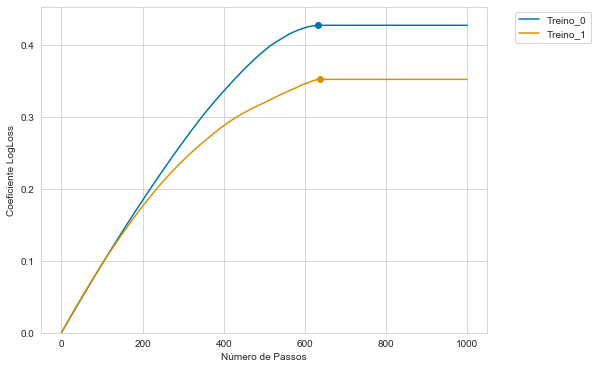

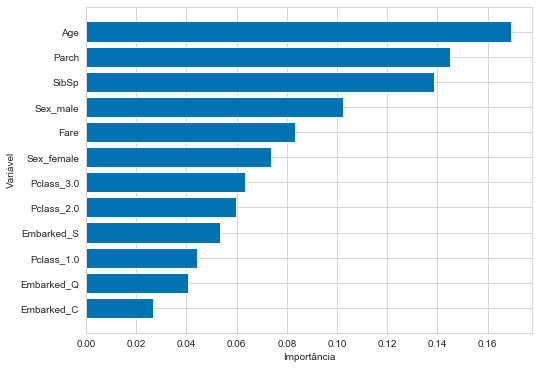

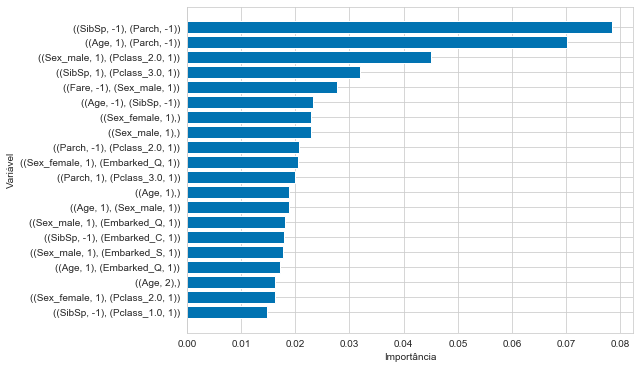

In [22]:
t = time.time()

clf = lrn.SeriesMultiGradientClassifier()
clf.setup_datasets(dict_Xy, laurent = True, ordem = 2, apenas_interacoes = False)
clf.setup_optimizer(alpha = 0.001, epsilon = 1e-8, early_stop = 0, filtro_atualizacao_thetas = True)
clf.fit(num_passos = 1000, verbose = 1, plot = False)

print(time.time() - t)

clf.grafico_vies_variancia(ymin = 0)
clf.grafico_importancias()
clf.grafico_importancias_termos(num_vars = 20)

In [23]:
df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)
df_teste_t = tratador.aplica_transformacao_ohe(df_teste, usar_ponto_medio = True)
    
probs_intermed = clf.predict_proba(df_intermed_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]
probs_teste = clf.predict_proba(df_teste_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1))[:, 1]

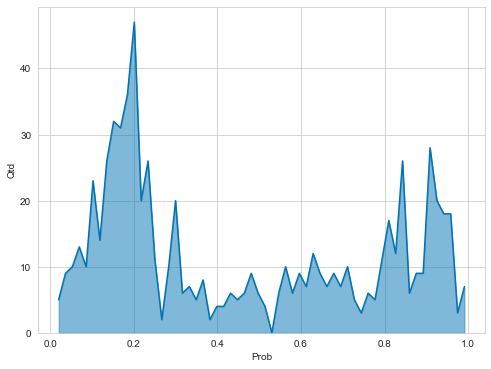

In [24]:
import seaborn as sns
import matplotlib.pyplot as plt

qtds, probs = np.histogram(probs_intermed, bins = 60)

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    axs.plot(probs[1:], qtds, color = paleta_cores[0])
    axs.fill_between(probs[1:], qtds, color = paleta_cores[0], alpha = 0.5)
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel('Prob')
    axs.set_ylabel('Qtd')
    #axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

In [25]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

df_intermed_aval['Prob'] = probs_intermed
df_teste_aval['Prob'] = probs_teste

In [26]:
dict_dfs = {'Treino': df_intermed_aval,
            'Teste': df_teste_aval}
avaliacaoclf = aml.AvaliaDatasetsClassificacao(dict_dfs, 
                                               nome_alvo, 
                                               'Prob', 
                                               num_div_prob = 50, 
                                               num_div = 10, 
                                               num_cat = 3, 
                                               unit = None, 
                                               chave_treino = 'Treino')

In [27]:
avaliacaoclf.valor_metricas()

Treino       Teste
QTD                          712.000000  179.000000
QTD_0                        439.000000  110.000000
QTD_1                        273.000000   69.000000
Frac_0                         0.616573    0.614525
Frac_1                         0.383427    0.385475
Soma_Prob                    318.888018   80.323239
Media_Prob                     0.447876    0.448733
[... 25 linhas omitidas na versão pública ...]
TVN_2D                         0.950437    0.940476
TVP_2D                         0.822115    0.822222
Acurácia_Balanceada_Cond       0.850564    0.825760
Acurácia_Balanceada_Cond_2D    0.903823    0.894499
P(0|0)                         0.824351    0.781955
P(1|1)                         0.876777    0.869565
P_2D(0|0)                      0.898072    0.908046
P_2D(1|1)                      0.909574    0.880952

In [28]:
avaliacaoclf.valor_metricas().loc[['LogLoss', 'CoefLogLoss', 'CoefLogLoss_ref',
                                  'AUC', 'KS', 'IG', 'IG_2D', 'Frac_Incerto_2D', 
                                  'Prob_Corte', 'Prob0_Corte', 'Prob1_Corte',
                                  'Acurácia_Balanceada', 'Acurácia_Balanceada_2D',
                                  'P(0|0)', 'P_2D(0|0)', 'Frac_0',
                                  'P(1|1)', 'P_2D(1|1)', 'Frac_1'], :]

Treino     Teste
LogLoss                 0.417186  0.451304
CoefLogLoss             0.373329  0.323059
CoefLogLoss_ref         0.373329  0.323068
AUC                     0.880685  0.875626
KS                      0.639207  0.620685
IG                      0.344769  0.295831
IG_2D                   0.398519  0.369528
Frac_Incerto_2D         0.226124  0.279330
Prob_Corte              0.698064  0.499552
Prob0_Corte             0.350100  0.331327
Prob1_Corte             0.767115  0.788979
Acurácia_Balanceada     0.809215  0.762582
Acurácia_Balanceada_2D  0.886276  0.881349
P(0|0)                  0.824351  0.781955
P_2D(0|0)               0.898072  0.908046
Frac_0                  0.616573  0.614525
P(1|1)                  0.876777  0.869565
P_2D(1|1)               0.909574  0.880952
Frac_1                  0.383427  0.385475

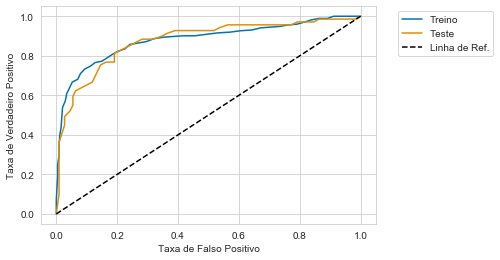

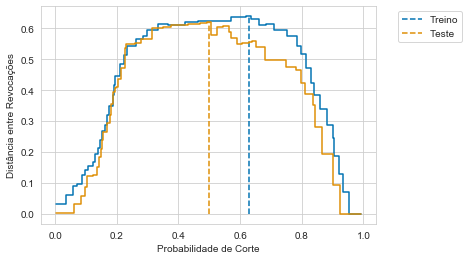

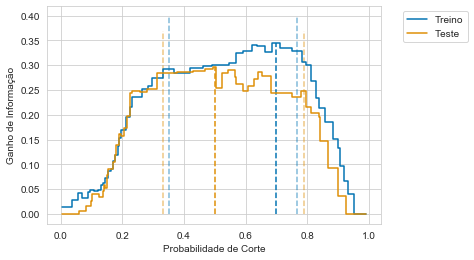

In [29]:
avaliacaoclf.grafico_roc()
avaliacaoclf.grafico_ks()
avaliacaoclf.grafico_informacao(mostrar_ig_2d = True)

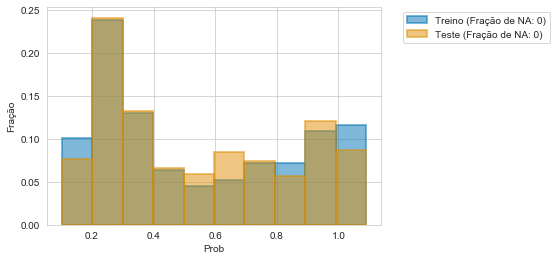

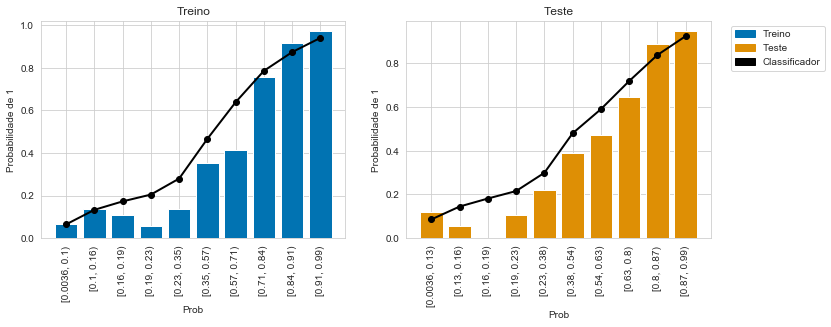

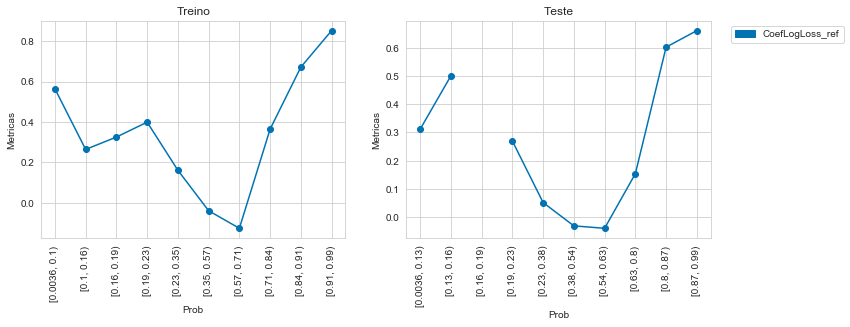

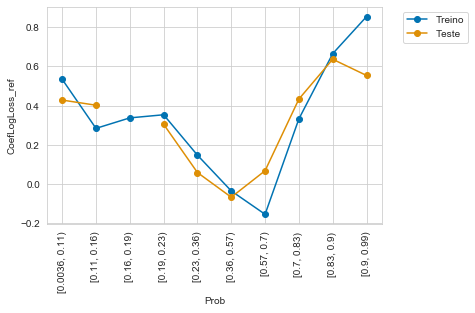

In [30]:
avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'Prob', num_div = 10, parametros_padrao = False)
avaliacaoclf.grafico_distribuicao('Prob')
avaliacaoclf.grafico_probabilidade_condicional('Prob', rot = 90)
avaliacaoclf.grafico_metricas_condicionais('Prob', metricas = ['CoefLogLoss_ref'], rot = 90)
avaliacaoclf.grafico_metrica_condicional_geral('Prob', metrica = 'CoefLogLoss_ref', rot = 90)

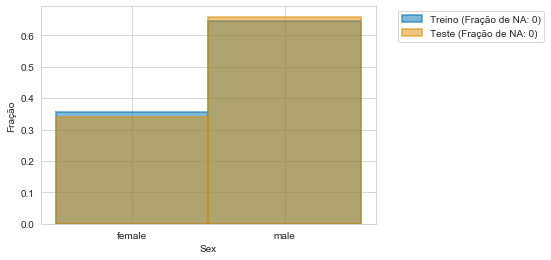

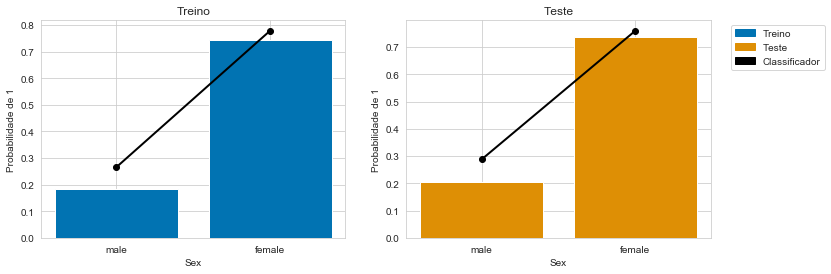

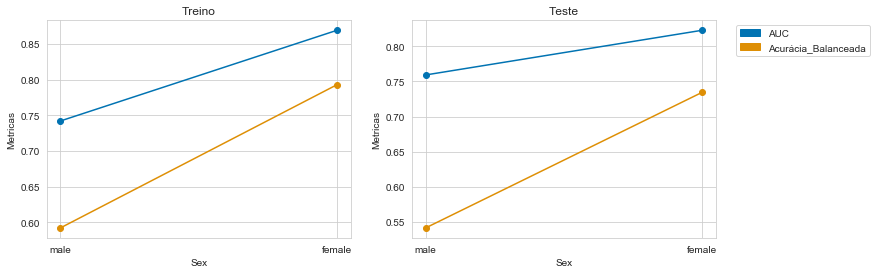

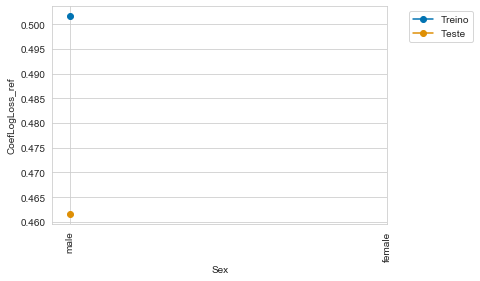

In [31]:
avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'Sex')
avaliacaoclf.grafico_distribuicao('Sex')
avaliacaoclf.grafico_probabilidade_condicional('Sex')
avaliacaoclf.grafico_metricas_condicionais('Sex', metricas = ['AUC', 'Acurácia_Balanceada'])
avaliacaoclf.grafico_metrica_condicional_geral('Sex', metrica = 'CoefLogLoss_ref', rot = 90)

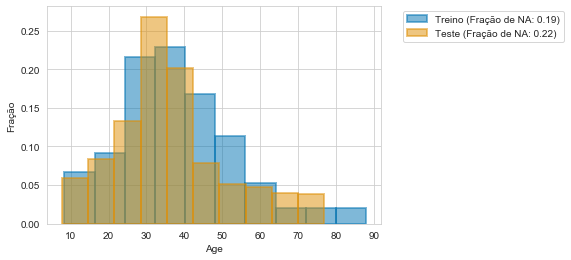

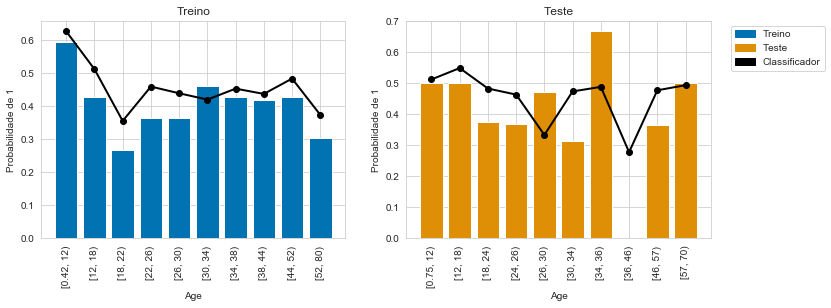

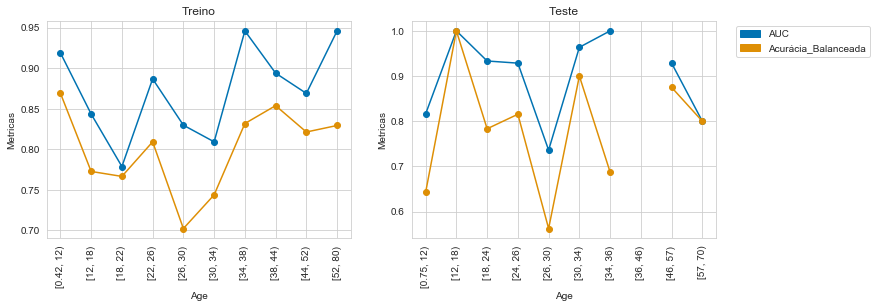

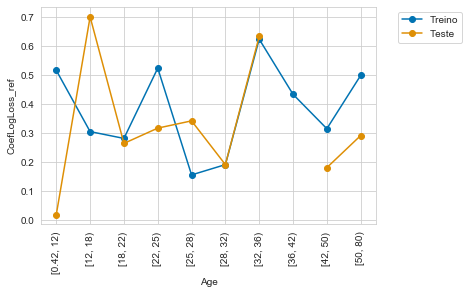

In [32]:
avaliacaoclf.calcula_metricas_condicionais(dict_dfs, 'Age')
avaliacaoclf.grafico_distribuicao('Age')
avaliacaoclf.grafico_probabilidade_condicional('Age', rot = 90)
avaliacaoclf.grafico_metricas_condicionais('Age', metricas = ['AUC', 'Acurácia_Balanceada'], rot = 90)
avaliacaoclf.grafico_metrica_condicional_geral('Age', metrica = 'CoefLogLoss_ref', rot = 90)

# Explainer Classificação

In [33]:
exp_clf = exp.ImportanciaVariaveisClassificacao(clf,
                                                df_intermed_t,
                                                nome_alvo,
                                                cols_features=['Age', 'SibSp', 'Parch', 'Fare',
                                                               'Sex_female', 'Sex_male', 
                                                               'Pclass_1.0', 'Pclass_2.0', 'Pclass_3.0',
                                                               'Embarked_C', 'Embarked_Q', 'Embarked_S'],
                                                num_loop=10,
                                                random_state=42,
                                                )

In [34]:
exp_clf.retorna_piora_logloss()

{'Age': 0.1553923130856094,
 'SibSp': 0.06978886029834408,
 'Parch': 0.030045881721819656,
 'Fare': 0.04369173000591209,
 'Sex_female': 0.13281633658245862,
 'Sex_male': 0.2170745975815691,
 'Pclass_1.0': 0.05471355514934473,
 'Pclass_2.0': 0.04529799917151278,
 'Pclass_3.0': 0.06332969730348181,
 'Embarked_C': 0.006127440917325533,
 'Embarked_Q': 0.018991264469553126,
 'Embarked_S': 0.0062503916810578986}

In [35]:
exp_clf.retorna_importancias()

{'Age': 0.1842188692202003,
 'SibSp': 0.08273526967350411,
 'Parch': 0.03561964067339757,
 'Fare': 0.05179690639863967,
 'Sex_female': 0.15745486281364787,
 'Sex_male': 0.25734372639704284,
 'Pclass_1.0': 0.06486337104124602,
 'Pclass_2.0': 0.053701151746909974,
 'Pclass_3.0': 0.07507787865206444,
 'Embarked_C': 0.007264131761661971,
 'Embarked_Q': 0.02251430071521883,
 'Embarked_S': 0.007409890906466375}

# CAM Classificador

In [36]:
cols_features = ['Age', 'SibSp', 'Parch', 'Fare',
       'Sex_female', 'Sex_male', 'Pclass_1.0', 'Pclass_2.0', 'Pclass_3.0',
       'Embarked_C', 'Embarked_Q', 'Embarked_S']

camclf = exp.CamClassificacao(clf, df_intermed_t, df_teste_t, cols_features = cols_features, num_loop = 25, 
                          random_state = 42)

In [37]:
for i in range(15, 30):
    display(camclf.styler_mapa_calor(df_teste_t.iloc[[i]], 
                                 ordenar_linhas = 'descending', ordenar_colunas = 'descending', 
                                 opacity_text = True))

# Regressor

In [38]:
colunas_id = ['PassengerId']
nome_alvo = 'Age'
df2 = df[~df['Age'].isna()]

In [39]:
#vars_cat = ['Sex', 'Pclass', 'Embarked', 'Survived']
vars_cat = ['Sex', 'Pclass', 'Embarked']
vars_num = [v for v in df.columns[2:] if v not in vars_cat and v != 'Age']

In [40]:
frac_teste = 0.2

ss_teste = ShuffleSplit(n_splits = 1, test_size = frac_teste, random_state = 42)
split_teste = list(ss_teste.split(df2.values, df2[nome_alvo].values))[0] 

df_intermed = df2.iloc[split_teste[0]]
df_teste = df2.iloc[split_teste[1]]

In [41]:
tratador = trf.TrataDataset(df_intermed, num_div = None, num_cat = None, 
                            features_numericas = vars_num,
                            features_categoricas = vars_cat)
tratador.cria_one_hot_encoder(df_intermed, considera_resto = True, usar_str = True)

df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)

In [42]:
frac_val = 0.2
num_splits = 4

ss = ShuffleSplit(n_splits = num_splits, test_size = frac_val, random_state = 42)
lista_splits = list(ss.split(df_intermed.values, df_intermed[nome_alvo].values))  

In [43]:
dict_Xy = {}

i = 0
for par in lista_splits:
    df_treino = df_intermed.iloc[par[0]]
    df_val = df_intermed.iloc[par[1]]
    
    df_treino_t = tratador.aplica_transformacao_ohe(df_treino, usar_ponto_medio = True)
    df_val_t = tratador.aplica_transformacao_ohe(df_val, usar_ponto_medio = True)
    
    dict_Xy.update({'Treino_' + str(2*i + 1): (df_treino_t.drop(colunas_id, axis = 1).drop([nome_alvo, 'Survived'], axis = 1), df_treino_t[nome_alvo]),
               'Treino_' + str(2*i + 2): (df_val_t.drop(colunas_id, axis = 1).drop([nome_alvo, 'Survived'], axis = 1), df_val_t[nome_alvo])})
    
    #dict_Xy.update({'Treino_' + str(i+1): (df_treino_t.drop(colunas_id, axis = 1).drop(nome_alvo, axis = 1), df_treino_t[nome_alvo])})
    
    i = i + 1

In [44]:
corta_interv = trf.CortaIntervalosQuasiUniforme(df_intermed[nome_alvo].values, num_div = 4)
valores_disc = corta_interv.aplica_discretizacao(df_intermed[nome_alvo].values)
dict_Xy = {}
for i in range(corta_interv.valores_medios_discretizacao().size):
    df_aux = df_intermed_t.loc[valores_disc == i, :]
    dict_Xy.update({'Treino_' + str(i+1): (df_aux.drop(colunas_id, axis = 1).drop([nome_alvo, 'Survived'], axis = 1), 
                                           df_aux[nome_alvo])})

Checando Datasets
Filtrando Features sem Variância
Criando a Expansão em Série
Número de Parâmetros da Expansão: 515
Calculando as Normalizações das Features
Número de Parâmetros: 358
Normalizando o Alvo
Criando o Baseline Constante
Inicializando os Parâmetros para Fitting
34.122565507888794


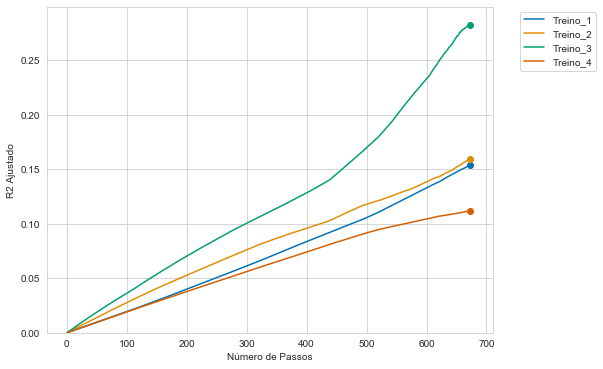

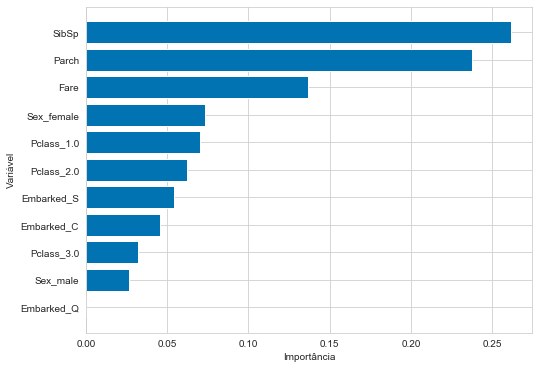

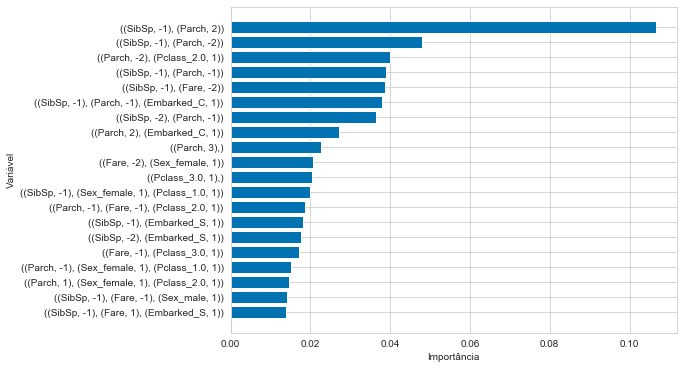

In [45]:
t = time.time()

rgs = lrn.SeriesMultiGradientRegressor()
rgs.setup_datasets(dict_Xy, laurent = True, ordem = 3, apenas_interacoes = False)
rgs.setup_optimizer(alpha = 0.0001, epsilon = 1e-8, early_stop = 0, filtro_atualizacao_thetas = False)
rgs.fit(num_passos = 1000, verbose = 0, plot = False)

print(time.time() - t)

rgs.grafico_vies_variancia(ymin = 0)
rgs.grafico_importancias()
rgs.grafico_importancias_termos(num_vars = 20)

In [46]:
df_intermed_t = tratador.aplica_transformacao_ohe(df_intermed, usar_ponto_medio = True)
df_teste_t = tratador.aplica_transformacao_ohe(df_teste, usar_ponto_medio = True)
    
preds_intermed = rgs.predict(df_intermed_t.drop(colunas_id, axis = 1).drop([nome_alvo, 'Survived'], axis = 1))
preds_teste = rgs.predict(df_teste_t.drop(colunas_id, axis = 1).drop([nome_alvo, 'Survived'], axis = 1))

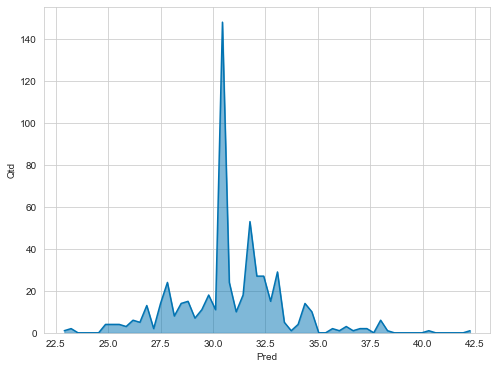

In [47]:
qtds, preds = np.histogram(preds_intermed, bins = 60)

paleta_cores = sns.color_palette("colorblind")
with sns.axes_style("whitegrid"):
    fig, axs = plt.subplots(1, 1, figsize = [8, 6])
    axs.plot(preds[1:], qtds, color = paleta_cores[0])
    axs.fill_between(preds[1:], qtds, color = paleta_cores[0], alpha = 0.5)
    axs.set_ylim(bottom = 0.0)
    axs.set_xlabel('Pred')
    axs.set_ylabel('Qtd')
    #axs.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.show()

In [48]:
df_intermed_aval = df_intermed.copy()
df_teste_aval = df_teste.copy()

df_intermed_aval['Pred'] = preds_intermed
df_teste_aval['Pred'] = preds_teste

In [49]:
dict_dfs = {'Treino': df_intermed_aval,
            'Teste': df_teste_aval}
avaliacaorgs = aml.AvaliaDatasetsRegressao(dict_dfs, 
                                               nome_alvo, 
                                               'Pred', 
                                               num_kendalltau = 10000, 
                                               num_div = 10, 
                                               num_cat = 3, 
                                               unit = None, 
                                               chave_treino = 'Treino')

In [50]:
avaliacaorgs.valor_metricas()

Treino        Teste
QTD                571.000000   143.000000
Soma_Alvo        17139.670000  4065.500000
Soma_Pred        17472.587848  4323.905764
Media_Alvo          30.016935    28.430070
Media_Pred          30.599979    30.237103
MAE                 10.496979    10.493052
MSE                187.664918   169.372727
RMSE                13.699085    13.014328
RAE                  0.918080     0.971685
RSE                  0.866572     0.913532
RRSE                 0.930898     0.955789
RAE_ref              0.918080     0.953313
RSE_ref              0.866572     0.901291
RRSE_ref             0.930898     0.949364
R1                   0.081920     0.028315
R2                   0.133428     0.086468
RR2                  0.069102     0.044211
R1_ref               0.081920     0.046687
R2_ref               0.133428     0.098709
RR2_ref              0.069102     0.050636
KendallTau_Conc      0.894300     0.683200
KendallTau_Disc      0.105700     0.316800
KendallTau           0.788600     0.366400
KS                   0.406305     0.426573
Coef_KS             -4.964654    -5.693850
Coef_KS_ref         -4.964654    -2.950990

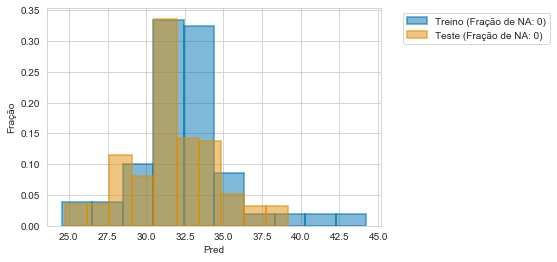

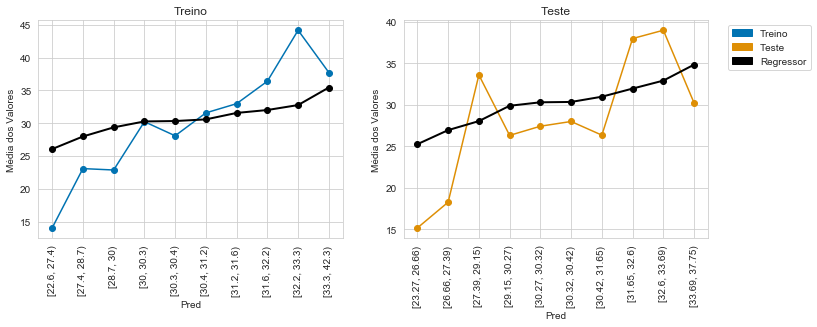

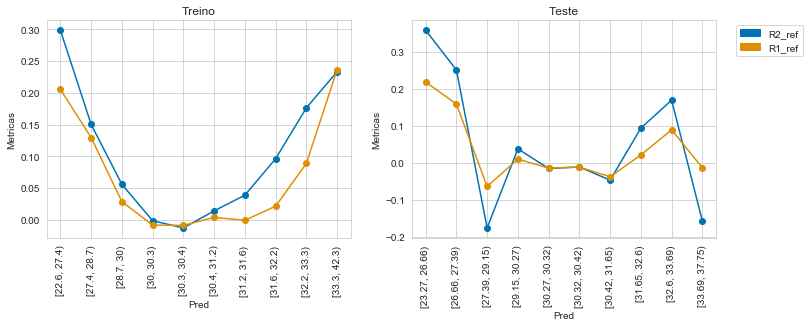

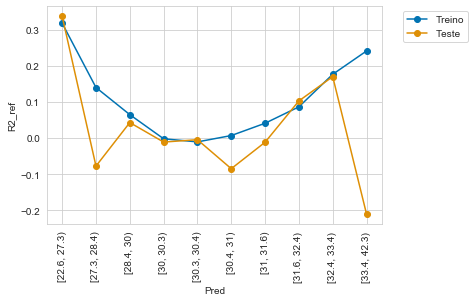

In [51]:
avaliacaorgs.calcula_metricas_condicionais(dict_dfs, 'Pred')
avaliacaorgs.grafico_distribuicao('Pred')
avaliacaorgs.grafico_media_condicional('Pred', rot = 90)
avaliacaorgs.grafico_metricas_condicionais('Pred', metricas = ['R2_ref', 'R1_ref'], rot = 90)
avaliacaorgs.grafico_metrica_condicional_geral('Pred', metrica = 'R2_ref', rot = 90)

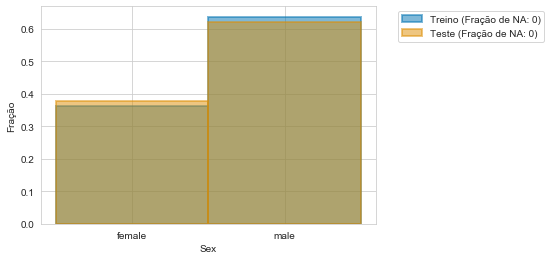

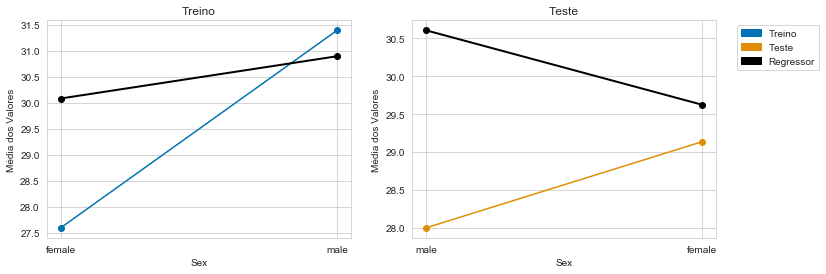

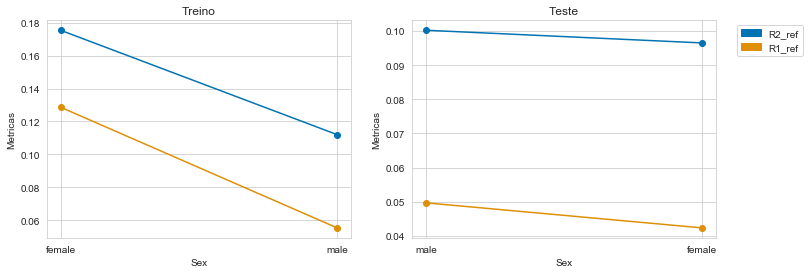

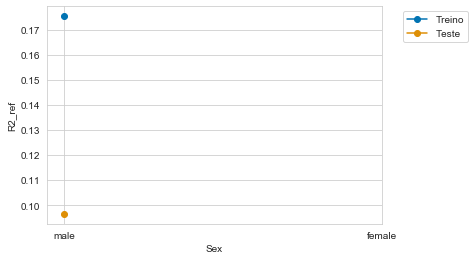

In [52]:
avaliacaorgs.calcula_metricas_condicionais(dict_dfs, 'Sex')
avaliacaorgs.grafico_distribuicao('Sex')
avaliacaorgs.grafico_media_condicional('Sex')
avaliacaorgs.grafico_metricas_condicionais('Sex', metricas = ['R2_ref', 'R1_ref'])
avaliacaorgs.grafico_metrica_condicional_geral('Sex', metrica = 'R2_ref')

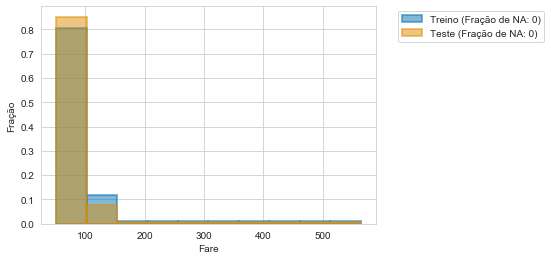

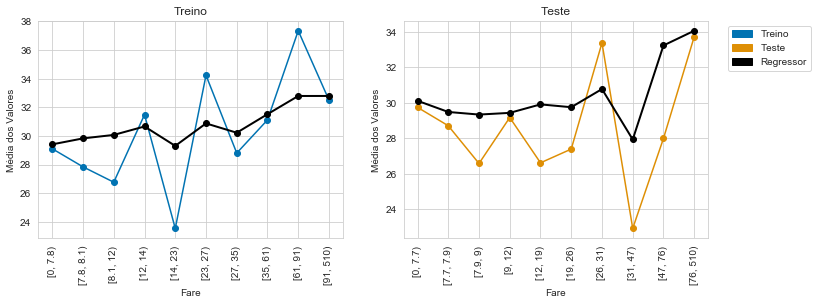

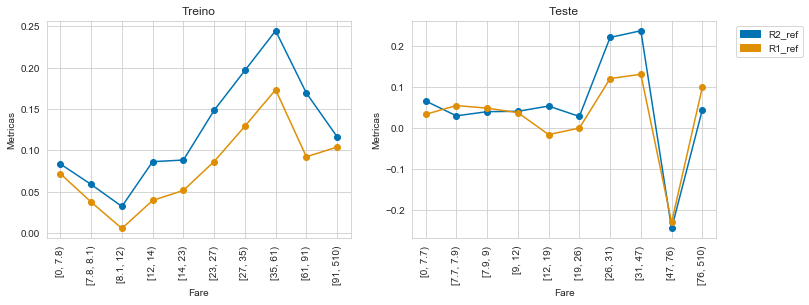

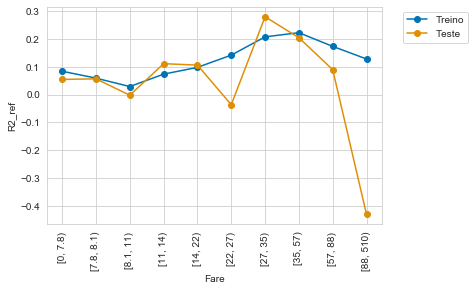

In [53]:
avaliacaorgs.calcula_metricas_condicionais(dict_dfs, 'Fare')
avaliacaorgs.grafico_distribuicao('Fare')
avaliacaorgs.grafico_media_condicional('Fare', rot = 90)
avaliacaorgs.grafico_metricas_condicionais('Fare', metricas = ['R2_ref', 'R1_ref'], rot = 90)
avaliacaorgs.grafico_metrica_condicional_geral('Fare', metrica = 'R2_ref', rot = 90)

# Explainer Regressor

In [54]:
exp_rgs = exp.ImportanciaVariaveisRegressao(rgs,
                                            df_intermed_t,
                                            nome_alvo,
                                            cols_features=['SibSp', 'Parch', 'Fare',
                                                           'Sex_female', 'Sex_male', 
                                                           'Pclass_1.0', 'Pclass_2.0', 'Pclass_3.0',
                                                           'Embarked_C', 'Embarked_Q', 'Embarked_S'],
                                            num_loop=10,
                                            random_state=42,
                                            )

In [55]:
exp_rgs.retorna_piora_mse()

{'SibSp': 0.06401565523237629,
 'Parch': 0.042958115391832585,
 'Fare': 0.003207071142528717,
 'Sex_female': 0.01282058302197786,
 'Sex_male': 0.0022043890158804924,
 'Pclass_1.0': 0.07078441749455577,
 'Pclass_2.0': 0.011176241352318206,
 'Pclass_3.0': 0.02340372875527441,
 'Embarked_C': 0.007131638739065638,
 'Embarked_Q': 5.7256724714793705e-06,
 'Embarked_S': -0.0033718188033214913}

In [56]:
exp_rgs.retorna_importancias()

{'SibSp': 0.2655376581985845,
 'Parch': 0.1781907460036844,
 'Fare': 0.013302967184699432,
 'Sex_female': 0.053179922630468744,
 'Sex_male': 0.00914383044133156,
 'Pclass_1.0': 0.2936145602232172,
 'Pclass_2.0': 0.04635917488283115,
 'Pclass_3.0': 0.09707893021217386,
 'Embarked_C': 0.02958211773378891,
 'Embarked_Q': 2.375015383611651e-05,
 'Embarked_S': 0.013986342335384181}

# Cam Regressor

In [57]:
cols_features = ['SibSp', 'Parch', 'Fare',
       'Sex_female', 'Sex_male', 'Pclass_1.0', 'Pclass_2.0', 'Pclass_3.0',
       'Embarked_C', 'Embarked_Q', 'Embarked_S']

camrgs = exp.CamRegressao(rgs, df_intermed_t, df_teste_t, cols_features = cols_features, num_loop = 25, 
                          random_state = 42)

In [58]:
for i in range(15, 30):
    display(camrgs.styler_mapa_calor(df_teste_t.iloc[[i]], 
                                 ordenar_linhas = 'descending', ordenar_colunas = 'descending', 
                                 opacity_text = True))